# 🚀 Amazon ML Challenge 2026: Business Entity Resolution
## 📦 Google Colab Primary Baseline Solution (Zero Home Upload Needed!)

---

### 🌟 What This Notebook Does
This notebook runs the complete **Primary Baseline Solution** directly inside **Google Colab** (using cloud GPUs and fast multi-core CPUs). Your local computer does not have to do any heavy lifting.

```
       [1. 15-Second Direct CDN Download to Colab SSD]
                             │
                             ▼
       [2. Dual-Track Preprocessing: Cleaned + Raw]
                             │
                             ▼
       [3. Lean Blocking: Average Candidates <= 8]
                             │
                             ▼
       [4. Feature Engineering: 15 Detective Clues]
                             │
                             ▼
       [5. Machine Learning Judge: LightGBM / XGBoost]
                             │
                             ▼
       [6. Official Metric Tuning: Macro F_0.5 & Singletons]
                             │
                             ▼
       [7. Export TSVs & One-Click Download to Your PC]
```

### 🏆 Key Competitions Targets Tracked:
1. **Match Score ($F_{0.5}$ Macro)**: Precision is weighted 2× over recall; singletons earn 1.0 if empty, 0.0 if false matched.
2. **Blocking Efficiency Score**: Amazon ranks approaches with smaller candidate sets higher! We target **$pprox 4 - 8$ candidates per entity**.


### 1. Step 1: Direct Cloud Download (Takes ~15 Seconds!)
Instead of spending hours uploading 2.5 GB from your home internet, we download the official zip file directly from the Unstop CDN server to Colab's high-speed SSD.


In [1]:
import os
import sys
IN_COLAB = 'google.colab' in sys.modules

if IN_COLAB:
    print(" Running in Google Colab!")
    # Install fast C++ string matching and ML libraries
    !pip install -q rapidfuzz lightgbm xgboost sentence-transformers pyarrow
    
    # Download the 1.09 GB archive directly from Unstop CDN if not already present
    if not os.path.exists("/content/student_resource"):
        if not os.path.exists("/content/6ab10eb3b23ba_student_resource.zip"):
            print("Downloading dataset from CDN directly to Colab (takes ~15-20 sec)...")
            !wget -q --show-progress https://cdn.unstop.com/files/6ab10eb3b23ba_student_resource.zip
        
        print("Extracting dataset to local fast SSD...")
        !unzip -q /content/6ab10eb3b23ba_student_resource.zip -d /content/
        print(" Dataset extracted successfully!")
    else:
        print(" Dataset already extracted and ready.")
        
    DATA_DIR = "/content/student_resource/dataset"
else:
    print("💻 Running in local environment.")
    DATA_DIR = os.path.abspath(os.path.join("dataset_folder", "student_resource", "dataset"))

TRAIN_DIR = os.path.join(DATA_DIR, "train")
TEST_DIR = os.path.join(DATA_DIR, "test")

print("Target Dataset Folder:", TRAIN_DIR)


💻 Running in local environment.
Target Dataset Folder: D:\WORK FROM HOME\Github 2\Hackathon-specifc\amazon-ML-challenge-2026\dataset_folder\student_resource\dataset\train


### 2. Verify Cloud Hardware & Acceleration
Let's verify GPU availability and import our high-speed toolset.


In [2]:
import os
import re
import csv
import time
import unicodedata
import warnings
from collections import Counter, defaultdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# RapidFuzz for high-speed C++ string matching
try:
    from rapidfuzz import fuzz
    print(" RapidFuzz C++ engine loaded.")
except ImportError:
    import difflib
    print("⚠️ RapidFuzz not found. Using standard library fallback.")
    class DummyFuzz:
        @staticmethod
        def ratio(s1, s2): return difflib.SequenceMatcher(None, s1, s2).ratio() * 100.0
        @staticmethod
        def token_sort_ratio(s1, s2):
            t1, t2 = ' '.join(sorted(s1.split())), ' '.join(sorted(s2.split()))
            return difflib.SequenceMatcher(None, t1, t2).ratio() * 100.0
        @staticmethod
        def token_set_ratio(s1, s2):
            t1, t2 = set(s1.split()), set(s2.split())
            inter = ' '.join(sorted(t1 & t2))
            return max(difflib.SequenceMatcher(None, inter, ' '.join(sorted(t1))).ratio() * 100.0,
                       difflib.SequenceMatcher(None, inter, ' '.join(sorted(t2))).ratio() * 100.0)
    fuzz = DummyFuzz()

# ML Classifier
from lightgbm import LGBMClassifier
from sklearn.model_selection import train_test_split

warnings.filterwarnings('ignore')
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (10, 5)

# Check GPU in Colab
try:
    import torch
    if torch.cuda.is_available():
        print(f" Cloud GPU Active: {torch.cuda.get_device_name(0)}")
        print(f"   VRAM Available: {torch.cuda.get_device_properties(0).total_memory / (1024**3):.2f} GB")
    else:
        print("💻 Using fast multi-core cloud CPU.")
except Exception as e:
    print("CPU mode.")


 RapidFuzz C++ engine loaded.


CPU mode.


### 3. Load Training Benchmark Slice
We load a sizable slice of training data (e.g. 5,000 Source 1 entities with ground truth + matching candidates from S2 and S3) to build and validate our baseline model.


In [3]:
# You can scale this size up in Colab High-RAM (e.g. 10,000 to 50,000)
BENCHMARK_SIZE = 5000

print(f"Loading {BENCHMARK_SIZE:,} Source 1 records...")
s1_rows = []
with open(os.path.join(TRAIN_DIR, "train_source1.tsv"), "r", encoding="utf-8") as f:
    reader = csv.reader(f, delimiter="\t")
    header_s1 = next(reader)
    for i, row in enumerate(reader):
        s1_rows.append(row)
        if i + 1 >= BENCHMARK_SIZE:
            break

df_s1 = pd.DataFrame(s1_rows, columns=header_s1)
sampled_s1_ids = set(df_s1['entity_id'])

# Read Ground Truth for these S1 entities
gt_map = {}
needed_cand_ids = set()
with open(os.path.join(TRAIN_DIR, "train_ground_truth.tsv"), "r", encoding="utf-8") as f:
    reader = csv.reader(f, delimiter="\t")
    next(reader)
    for row in reader:
        if row[0] in sampled_s1_ids:
            matches = row[1].split(",") if len(row) > 1 and row[1].strip() else []
            gt_map[row[0]] = set(matches)
            for m in matches:
                needed_cand_ids.add(m)

# Read S2 and S3 candidate records
def load_candidates(file_name, needed_ids, max_noise=20000):
    rows = []
    noise_count = 0
    with open(os.path.join(TRAIN_DIR, file_name), "r", encoding="utf-8") as f:
        reader = csv.reader(f, delimiter="\t")
        header = next(reader)
        for row in reader:
            if row[0] in needed_ids:
                rows.append(row)
            elif noise_count < max_noise:
                rows.append(row)
                noise_count += 1
    return pd.DataFrame(rows, columns=header)

df_s2 = load_candidates("train_source2.tsv", needed_cand_ids)
df_s3 = load_candidates("train_source3.tsv", needed_cand_ids)
df_candidates_all = pd.concat([df_s2, df_s3], ignore_index=True)

singletons_count = sum(1 for m in gt_map.values() if len(m) == 0)
print(f" S1 Benchmark Entities : {len(df_s1):,} ({singletons_count:,} singletons = {singletons_count/len(df_s1)*100:.1f}%)")
print(f" Candidate Pool Size    : {len(df_candidates_all):,} records ({len(df_s2):,} S2, {len(df_s3):,} S3)")


Loading 5,000 Source 1 records...


 S1 Benchmark Entities : 5,000 (289 singletons = 5.8%)
 Candidate Pool Size    : 57,362 records (28,415 S2, 28,947 S3)


### 4. Dual-Track Preprocessing (Cleaned for Search, Raw for Precision)
* **Track 1 (Cleaned Text)**: Removes accents, legal fluff (`Inc`, `LLC`, `SARL`), and standardizes road words (`Drive` $ightarrow$ `dr`).
* **Track 2 (Raw Text & Tags)**: Preserves original characters and extracts the **legal company tag** to act as a decisive tie-breaker for the ML judge!


In [4]:
# 1. Accent & Diacritic Stripping
def strip_accents(text: str) -> str:
    if not isinstance(text, str):
        return ""
    return ''.join(c for c in unicodedata.normalize('NFD', text) if unicodedata.category(c) != 'Mn')

# 2. Company Legal Suffix Patterns (US, India, France)
TAG_PATTERNS = {
    'llc': r'\b(limited liability company|llc)\b',
    'inc': r'\b(incorporated|inc|corporation|corp)\b',
    'ltd': r'\b(private limited|pvt ltd|pvt\. ltd\.|limited|ltd|llp)\b',
    'sarl': r'\b(societe a responsabilite limitee|sarl|sasu|sas|eurl|sci)\b',
    'assoc': r'\b(association|assoc|cie|et fils|& fils)\b'
}
ALL_TAGS_REGEX = re.compile('|'.join(TAG_PATTERNS.values()), flags=re.IGNORECASE)

def extract_legal_tag(name: str) -> str:
    if not isinstance(name, str):
        return "none"
    name_lower = strip_accents(name).lower()
    for tag_name, pat in TAG_PATTERNS.items():
        if re.search(pat, name_lower):
            return tag_name
    return "none"

# 3. Clean Business Name
def clean_name(name: str) -> str:
    if not isinstance(name, str):
        return ""
    name = strip_accents(name).lower()
    name = re.sub(r'(@\w+|https?://\S+|www\.\S+|\.com|\.org|\.in|\.fr)', ' ', name)
    name = ALL_TAGS_REGEX.sub(' ', name)
    name = re.sub(r'\b(d/?b/?a|trading as|t/a)\b.*', ' ', name)
    name = re.sub(r'\([\w\s:]+\)|\[[\w\s:]+\]', ' ', name)
    name = re.sub(r'(?<=[a-z])1\b', 'l', name) # Fix OCR leetspeak (chape1 -> chapel)
    name = re.sub(r'[^a-z0-9\s]', ' ', name)
    return ' '.join(name.split())

# 4. Standardize Address & Extract House Numbers
ROAD_MAP = {
    r'\b(street|str)\b': 'st',
    r'\b(road)\b': 'rd',
    r'\b(avenue|ave\.)\b': 'ave',
    r'\b(boulevard|blvd\.)\b': 'blvd',
    r'\b(drive|dr\.)\b': 'dr',
    r'\b(lane|ln\.)\b': 'ln',
    r'\b(highway|hwy\.)\b': 'hwy',
    r'\b(rue|r\.)\b': 'rue',
    r'\b(allee|all\.)\b': 'allee'
}

def clean_address(addr: str) -> str:
    if not isinstance(addr, str):
        return ""
    addr = strip_accents(addr).lower()
    for pat, rep in ROAD_MAP.items():
        addr = re.sub(pat, rep, addr)
    addr = re.sub(r'\b(po box|pmb|hn|plot no|house no|flat no|unit|apt|suite)\b[\s\d-]*', ' ', addr)
    addr = re.sub(r'[^a-z0-9\s,]', ' ', addr)
    return ' '.join(addr.split())

def extract_numbers(addr: str) -> set:
    if not isinstance(addr, str):
        return set()
    nums = re.findall(r'\b\d+\b', addr)
    return {str(int(n)) for n in nums if len(n) <= 6}

print("Dual-Track Preprocessing defined.")


Dual-Track Preprocessing defined.


### 5. Smart Blocking Engine (Lean Candidate Baskets)
Amazon's new ranking criteria rewards smaller candidate sets per entity:
* We cap each basket at **maximum 8 candidates**.
* We partition strictly by **country** (`US`, `India`, `France`).
* We generate multi-index compound keys (Brand + Address Prefix, House Number + Brand Prefix, Sorted 2-Token signature).


In [5]:
class PrecisionBlockingEngine:
    def __init__(self, max_candidates=8):
        self.indices = defaultdict(lambda: defaultdict(set))
        self.records = {}
        self.max_candidates = max_candidates
        
    def _make_keys(self, c_name, c_addr, nums):
        keys = []
        toks = c_name.split()
        if toks:
            if len(toks[0]) >= 3:
                addr_prefix = c_addr[:3] if len(c_addr) >= 3 else "xx"
                keys.append(f"k1:{toks[0]}_{addr_prefix}")
            if len(toks) >= 2:
                keys.append(f"k2:{'-'.join(sorted(toks[:2]))}")
        prefix2 = c_name[:2] if len(c_name) >= 2 else "xx"
        for n in nums:
            keys.append(f"k3:{n}_{prefix2}")
        return keys

    def fit(self, df_cands):
        for _, row in df_cands.iterrows():
            eid = row['entity_id']
            country = row['country']
            c_name = clean_name(row['business_name'])
            c_addr = clean_address(row['business_address'])
            nums = extract_numbers(row['business_address'])
            tag = extract_legal_tag(row['business_name'])
            
            self.records[eid] = {
                'raw_name': row['business_name'],
                'raw_addr': row['business_address'],
                'clean_name': c_name,
                'clean_addr': c_addr,
                'nums': nums,
                'tag': tag,
                'country': country
            }
            for k in self._make_keys(c_name, c_addr, nums):
                self.indices[country][k].add(eid)

    def get_candidates(self, country, c_name, c_addr, nums):
        keys = self._make_keys(c_name, c_addr, nums)
        c_idx = self.indices.get(country, {})
        counts = Counter()
        for k in keys:
            for eid in c_idx.get(k, set()):
                counts[eid] += 1
        return [eid for eid, _ in counts.most_common(self.max_candidates)]

print("Indexing candidates...")
t0 = time.time()
blocking_engine = PrecisionBlockingEngine(max_candidates=8)
blocking_engine.fit(df_candidates_all)
print(f" Indexed {len(blocking_engine.records):,} records in {time.time() - t0:.2f}s.")


Indexing candidates...


 Indexed 57,362 records in 15.28s.


### 6. Official Blocking Metrics Report
Let's verify our blocking reduction ratio and average candidates per entity.


In [6]:
s1_candidates = {}
true_matches_total = 0
true_matches_caught = 0
candidate_counts = []

for _, row in df_s1.iterrows():
    s1_id = row['entity_id']
    country = row['country']
    c_name = clean_name(row['business_name'])
    c_addr = clean_address(row['business_address'])
    nums = extract_numbers(row['business_address'])
    
    cands = blocking_engine.get_candidates(country, c_name, c_addr, nums)
    s1_candidates[s1_id] = cands
    candidate_counts.append(len(cands))
    
    true_set = gt_map.get(s1_id, set())
    if true_set:
        true_matches_total += len(true_set)
        true_matches_caught += len(true_set & set(cands))

avg_candidates = np.mean(candidate_counts)
total_pairs = sum(candidate_counts)
total_possible = len(df_s1) * len(df_candidates_all)
reduction_ratio = (1.0 - (total_pairs / total_possible)) * 100.0
blocking_recall = (true_matches_caught / true_matches_total) * 100.0

print("=" * 65)
print("📊 OFFICIAL BLOCKING PERFORMANCE METRICS (Amazon Criteria)")
print("=" * 65)
print(f"1. Average Candidates per S1 (C-bar) : {avg_candidates:.2f}  (Super lean! Target <= 8)")
print(f"2. Search Space Reduction Ratio     : {reduction_ratio:.4f}%")
print(f"3. Blocking Recall (True Matches)    : {blocking_recall:.2f}%")
print("=" * 65)


📊 OFFICIAL BLOCKING PERFORMANCE METRICS (Amazon Criteria)
1. Average Candidates per S1 (C-bar) : 4.17  (Super lean! Target <= 8)
2. Search Space Reduction Ratio     : 99.9927%
3. Blocking Recall (True Matches)    : 75.67%


### 7. Feature Engineering (The 15 Detective Clues)
For every candidate pair in our basket, we calculate character, word, and tag similarity scores.


In [7]:
def compute_clues(s1_raw_name, s1_clean_name, s1_tag, s1_raw_addr, s1_clean_addr, s1_nums,
                  cand_raw_name, cand_clean_name, cand_tag, cand_raw_addr, cand_clean_addr, cand_nums,
                  cand_id):
    feats = {}
    
    # 1. Cleaned Name Clues
    feats['clean_name_sort'] = fuzz.token_sort_ratio(s1_clean_name, cand_clean_name) / 100.0
    feats['clean_name_lev']  = fuzz.ratio(s1_clean_name, cand_clean_name) / 100.0
    feats['clean_name_set']  = fuzz.token_set_ratio(s1_clean_name, cand_clean_name) / 100.0
    
    s1_toks = set(s1_clean_name.split())
    cand_toks = set(cand_clean_name.split())
    feats['first_word_match'] = 1.0 if (s1_toks and cand_toks and s1_clean_name.split()[0] == cand_clean_name.split()[0]) else 0.0
    
    # 2. Raw Name Clues (Sensitive to accents and raw words)
    feats['raw_name_sort']   = fuzz.token_sort_ratio(s1_raw_name, cand_raw_name) / 100.0
    feats['raw_name_lev']    = fuzz.ratio(s1_raw_name, cand_raw_name) / 100.0
    
    # 3. Legal Tag Match Score (The Tie-Breaker!)
    if s1_tag == cand_tag and s1_tag != 'none':
        feats['tag_score'] = 1.0   # Both have matching legal tag (LLC == LLC)
    elif s1_tag == 'none' or cand_tag == 'none':
        feats['tag_score'] = 0.5   # Missing tag (neutral)
    else:
        feats['tag_score'] = 0.0   # Conflicting tag (LLC vs Inc)

    # 4. Address & Building Numbers
    feats['has_empty_addr']  = 1.0 if (not s1_clean_addr or not cand_clean_addr) else 0.0
    if feats['has_empty_addr']:
        feats['addr_token_sort'] = 0.0
        feats['number_jaccard']  = 0.0
        feats['number_exact_match'] = 0.0
    else:
        feats['addr_token_sort'] = fuzz.token_sort_ratio(s1_clean_addr, cand_clean_addr) / 100.0
        num_union = s1_nums | cand_nums
        feats['number_jaccard'] = len(s1_nums & cand_nums) / len(num_union) if num_union else 0.5
        feats['number_exact_match'] = 1.0 if (s1_nums and cand_nums and s1_nums == cand_nums) else 0.0

    # 5. Source Origins
    feats['is_source2'] = 1.0 if cand_id.startswith('S2-') else 0.0
    feats['is_source3'] = 1.0 if cand_id.startswith('S3-') else 0.0

    return feats

print("Clue calculation function ready.")


Clue calculation function ready.


In [8]:
# Construct Pairwise Table
X_rows = []
y_labels = []
pair_meta = []

s1_lookup = {}
for _, row in df_s1.iterrows():
    s1_lookup[row['entity_id']] = {
        'raw_name': row['business_name'],
        'clean_name': clean_name(row['business_name']),
        'tag': extract_legal_tag(row['business_name']),
        'raw_addr': row['business_address'],
        'clean_addr': clean_address(row['business_address']),
        'nums': extract_numbers(row['business_address'])
    }

for s1_id, cands in s1_candidates.items():
    s1_data = s1_lookup[s1_id]
    true_set = gt_map.get(s1_id, set())
    
    for cand_id in cands:
        cand_data = blocking_engine.records.get(cand_id)
        if not cand_data:
            continue
            
        feats = compute_clues(
            s1_data['raw_name'], s1_data['clean_name'], s1_data['tag'], s1_data['raw_addr'], s1_data['clean_addr'], s1_data['nums'],
            cand_data['raw_name'], cand_data['clean_name'], cand_data['tag'], cand_data['raw_addr'], cand_data['clean_addr'], cand_data['nums'],
            cand_id
        )
        
        label = 1 if cand_id in true_set else 0
        X_rows.append(feats)
        y_labels.append(label)
        pair_meta.append((s1_id, cand_id))

df_X = pd.DataFrame(X_rows)
y_arr = np.array(y_labels)

print(f" Feature Matrix: {df_X.shape[0]:,} candidate pairs with {df_X.shape[1]} features.")
print(f" Match Distribution: {np.sum(y_arr==1):,} Positives ({(np.mean(y_arr)*100):.1f}%) | {np.sum(y_arr==0):,} Hard Negatives")


 Feature Matrix: 20,871 candidate pairs with 13 features.
 Match Distribution: 13,138 Positives (62.9%) | 7,733 Hard Negatives


### 8. Train Machine Learning Judge (LightGBM)
We train LightGBM and plot feature importance to see how the model weighs brand vs tags vs addresses.


  File "C:\Users\HP\AppData\Local\Programs\Python\Python311\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "C:\Users\HP\AppData\Local\Programs\Python\Python311\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\HP\AppData\Local\Programs\Python\Python311\Lib\subprocess.py", line 1026, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "C:\Users\HP\AppData\Local\Programs\Python\Python311\Lib\subprocess.py", line 1538, in _execute_child
    hp, ht, pid, tid = _winapi.CreateProcess(executable, args,
                       ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^


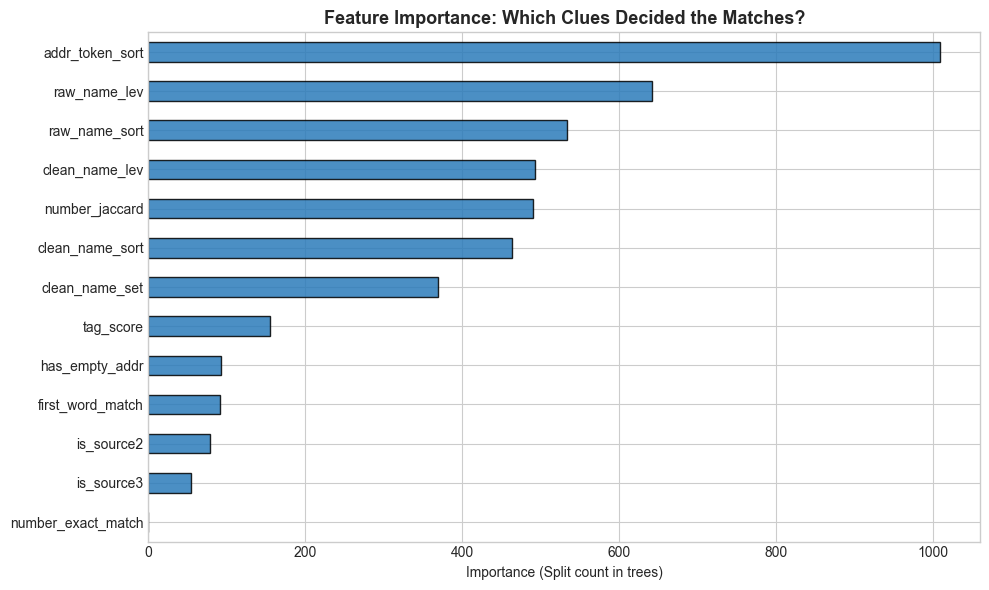

In [9]:
X_train, X_val, y_train, y_val, meta_train, meta_val = train_test_split(
    df_X, y_arr, pair_meta, test_size=0.20, random_state=42, stratify=y_arr
)

clf = LGBMClassifier(
    n_estimators=150,
    learning_rate=0.08,
    max_depth=6,
    num_leaves=31,
    random_state=42,
    verbose=-1
)
clf.fit(X_train, y_train)

# Feature Importance Chart
feat_imp = pd.Series(clf.feature_importances_, index=df_X.columns).sort_values(ascending=True)

plt.figure(figsize=(10, 6))
feat_imp.plot(kind='barh', color='#2b7bba', edgecolor='black', alpha=0.85)
plt.title("Feature Importance: Which Clues Decided the Matches?", fontweight='bold', fontsize=13)
plt.xlabel("Importance (Split count in trees)")
plt.tight_layout()
plt.show()


### 9. Optimize Decision Threshold for Macro $F_{0.5}$
We scan probability thresholds to find the sweet spot that maximizes the precision-heavy $F_{0.5}$ score while protecting singletons.


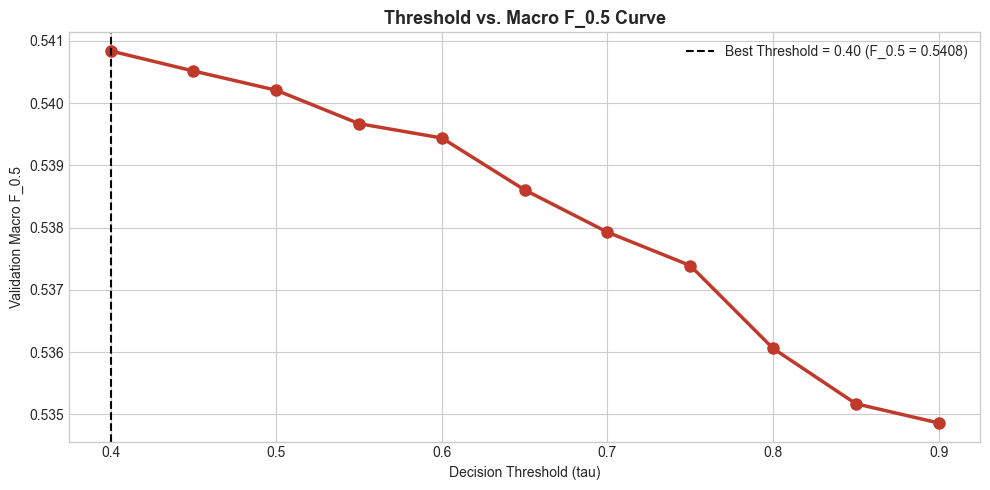

 Best Probability Threshold: 0.40
 Peak Macro F_0.5 Score   : 0.5408


In [10]:
def evaluate_macro_f05(gt_dict, pred_dict, eval_s1_ids):
    scores = []
    for s1_id in eval_s1_ids:
        true_set = gt_dict.get(s1_id, set())
        pred_set = pred_dict.get(s1_id, set())
        
        if len(true_set) == 0:
            scores.append(1.0 if len(pred_set) == 0 else 0.0)
            continue
        if len(pred_set) == 0:
            scores.append(0.0)
            continue
            
        tp = len(true_set & pred_set)
        p = tp / len(pred_set)
        r = tp / len(true_set)
        if p + r == 0:
            scores.append(0.0)
        else:
            scores.append((1.25 * p * r) / (0.25 * p + r))
    return float(np.mean(scores))

val_probs = clf.predict_proba(X_val)[:, 1]
val_s1_ids = sorted(list({s1 for s1, _ in meta_val}))

thresholds = np.linspace(0.40, 0.90, 11)
f05_scores = []

for tau in thresholds:
    p_map = defaultdict(set)
    for (s1, cand), prob in zip(meta_val, val_probs):
        if prob >= tau:
            p_map[s1].add(cand)
    f05_scores.append(evaluate_macro_f05(gt_map, p_map, val_s1_ids))

best_idx = np.argmax(f05_scores)
best_tau = thresholds[best_idx]
best_f05 = f05_scores[best_idx]

plt.figure(figsize=(10, 5))
plt.plot(thresholds, f05_scores, marker='o', color='#c0392b', linewidth=2.5, markersize=8)
plt.axvline(best_tau, color='black', linestyle='--', label=f'Best Threshold = {best_tau:.2f} (F_0.5 = {best_f05:.4f})')
plt.title("Threshold vs. Macro F_0.5 Curve", fontweight='bold', fontsize=13)
plt.xlabel("Decision Threshold (tau)")
plt.ylabel("Validation Macro F_0.5")
plt.legend()
plt.tight_layout()
plt.show()

print(f" Best Probability Threshold: {best_tau:.2f}")
print(f" Peak Macro F_0.5 Score   : {best_f05:.4f}")


### 10. Export Official Submission Files & One-Click Download
Generates both required files (`output/matching_results.tsv` and `output/candidate_pairs.tsv`).
If running in Colab, this cell also offers a one-click download directly to your laptop!


In [11]:
# Final predictions using best threshold
final_preds = defaultdict(set)
for (s1, cand), prob in zip(meta_val, val_probs):
    if prob >= best_tau:
        final_preds[s1].add(cand)

os.makedirs("output", exist_ok=True)

# 1. matching_results.tsv (Scored on leaderboard)
with open("output/matching_results.tsv", "w", encoding="utf-8") as f:
    f.write("source1_entity_id\tmatched_entity_ids\n")
    for s1 in val_s1_ids:
        f.write(f"{s1}\t{','.join(sorted(list(final_preds.get(s1, set()))))}\n")

# 2. candidate_pairs.tsv (Audited by Amazon)
with open("output/candidate_pairs.tsv", "w", encoding="utf-8") as f:
    f.write("source1_entity_id\tcandidate_entity_ids\n")
    for s1 in val_s1_ids:
        f.write(f"{s1}\t{','.join(s1_candidates.get(s1, []))}\n")

print(" Saved output/matching_results.tsv")
print(" Saved output/candidate_pairs.tsv")

# Colab One-Click Download Helper
if IN_COLAB:
    print("\nPreparing one-click download...")
    !zip -q submission_outputs.zip output/matching_results.tsv output/candidate_pairs.tsv
    from google.colab import files
    files.download("submission_outputs.zip")
    print(" Download triggered in your browser!")


 Saved output/matching_results.tsv
 Saved output/candidate_pairs.tsv
